<center><h1>Groome_Henry_HW7</h1></center>

Name: Henry Groome
<br>
Github Username: hgroome46
<br>
USC ID: 4479346040

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [4]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler

### (a) Download the Anuran Calls (MFCCs) Data Set

In [3]:

df = pd.read_csv("Anuran Calls (MFCCs)/Frogs_MFCCs.csv")
print(df.shape)  

X = df.iloc[:, :22]


Y = df[["Family", "Genus", "Species"]]


X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, train_size=0.7, random_state=42
)
print(X_train.shape, X_test.shape)  

(7195, 26)
(5036, 22) (2159, 22)


### (b) Train a classifier for each label

#### (i) Research

For multi-label classification has a few scoring methods. Exact match only rewards rows where the label is correct for all labels. Hamming score is the amount of labels correct in a row, divided by amount of total labels in that row, over all rows. Hamming loss is simply the opposite of this, so it's 1-hamming score, meaning that the lower this value is the more accurate it is. There's also hamming distance which is the count of wrong labels in a row, averaged over all rows. 

In [5]:
def exact_match(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    row_all_correct = np.all(y_true == y_pred, axis=1)
    return row_all_correct.mean()

def hamming_score(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return (y_true == y_pred).mean()

def hamming_loss(y_true, y_pred):
    return 1 - hamming_score(y_true, y_pred)

def hamming_distance(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return (y_true != y_pred).sum(axis=1).mean()

#### (ii) Train a SVM for each of the labels

In [6]:
C_values = [0.1, 1, 10, 100, 1000]
sigma_values = [0.1, 0.2, 0.5, 1, 2]
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

def find_best_params(X_tr, y_tr, C_values, sigma_values):
    best_score = -1
    best_C = None
    best_sigma = None
    for C in C_values:
        for sigma in sigma_values:
            gamma = 1 / (2 * sigma ** 2)
            model = OneVsRestClassifier(SVC(kernel="rbf", C=C, gamma=gamma))
            scores = cross_val_score(model, X_tr, y_tr, cv=cv, n_jobs=-1)
            mean_score = scores.mean()
            if mean_score > best_score:
                best_score = mean_score
                best_C = C
                best_sigma = sigma
    return best_C, best_sigma, best_score


def run_all_labels(X_tr, X_te, C_values, sigma_values):
    predictions = {}
    for label in ["Family", "Genus", "Species"]:
        best_C, best_sigma, best_score = find_best_params(X_tr, Y_train[label], C_values, sigma_values)
        print(f"{label}: C={best_C}, sigma={best_sigma}, cv accuracy={best_score:.4f}")
        final_model = OneVsRestClassifier(
            SVC(kernel="rbf", C=best_C, gamma=1 / (2 * best_sigma ** 2))
        )
        final_model.fit(X_tr, Y_train[label])
        predictions[label] = final_model.predict(X_te)
    return pd.DataFrame(predictions)




In [7]:
preds_raw = run_all_labels(X_train, X_test, C_values, sigma_values)
print("exact match:", exact_match(Y_test, preds_raw))
print("hamming score:", hamming_score(Y_test, preds_raw))
print("hamming loss:", hamming_loss(Y_test, preds_raw))


scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

sigma_values_std = [1, 2, 3, 5, 8]
preds_std = run_all_labels(X_train_std, X_test_std, C_values, sigma_values_std)
print("exact match:", exact_match(Y_test, preds_std))
print("hamming score:", hamming_score(Y_test, preds_std))
print("hamming loss:", hamming_loss(Y_test, preds_std))

Family: C=100, sigma=0.5, cv accuracy=0.9927
Genus: C=10, sigma=0.5, cv accuracy=0.9915
Species: C=100, sigma=0.5, cv accuracy=0.9911
exact match: 0.9888837424733673
hamming score: 0.9924347691832639
hamming loss: 0.0075652308167361015
Family: C=100, sigma=3, cv accuracy=0.9921
Genus: C=10, sigma=3, cv accuracy=0.9919
Species: C=10, sigma=3, cv accuracy=0.9909
exact match: 0.9865678554886521
hamming score: 0.9898100972672533
hamming loss: 0.01018990273274667


#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [8]:
from sklearn.svm import LinearSVC

C_values_l1 = [0.001, 0.01, 0.1, 1, 10, 100, 1000]

def find_best_C_l1(X_tr, y_tr, C_values):
    best_score = -1
    best_C = None
    for C in C_values:
        model = LinearSVC(penalty="l1", dual=False, C=C, max_iter=10000)
        scores = cross_val_score(model, X_tr, y_tr, cv=cv, n_jobs=-1)
        mean_score = scores.mean()
        if mean_score > best_score:
            best_score = mean_score
            best_C = C
    return best_C, best_score


def run_all_labels_l1(X_tr, X_te, C_values):
    predictions = {}
    for label in ["Family", "Genus", "Species"]:
        best_C, best_score = find_best_C_l1(X_tr, Y_train[label], C_values)
        final_model = LinearSVC(penalty="l1", dual=False, C=best_C, max_iter=10000)
        final_model.fit(X_tr, Y_train[label])
        nonzero = (final_model.coef_ != 0).sum()
        total = final_model.coef_.size
        print(f"{label}: C={best_C}, cv accuracy={best_score:.4f}, nonzero weights={nonzero}/{total}")
        predictions[label] = final_model.predict(X_te)
    return pd.DataFrame(predictions)



In [9]:
preds_l1_raw = run_all_labels_l1(X_train, X_test, C_values_l1)
print("exact match:", exact_match(Y_test, preds_l1_raw))
print("hamming score:", hamming_score(Y_test, preds_l1_raw))
print("hamming loss:", hamming_loss(Y_test, preds_l1_raw))

preds_l1_std = run_all_labels_l1(X_train_std, X_test_std, C_values_l1)
print("exact match:", exact_match(Y_test, preds_l1_std))
print("hamming score:", hamming_score(Y_test, preds_l1_std))
print("hamming loss:", hamming_loss(Y_test, preds_l1_std))

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increas

Family: C=100, cv accuracy=0.9400, nonzero weights=86/88


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increas

Genus: C=1000, cv accuracy=0.9516, nonzero weights=176/176


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increas

Species: C=1000, cv accuracy=0.9599, nonzero weights=220/220
exact match: 0.9106067623899954
hamming score: 0.9431835726416551
hamming loss: 0.05681642735834491
Family: C=10, cv accuracy=0.9412, nonzero weights=88/88


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Genus: C=1000, cv accuracy=0.9517, nonzero weights=176/176


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Species: C=10, cv accuracy=0.9607, nonzero weights=220/220
exact match: 0.9124594719777674
hamming score: 0.9430291801760075
hamming loss: 0.05697081982399255


#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [11]:


from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

def make_smote_model(C):
    return ImbPipeline([
        ("smote", SMOTE(random_state=42)),
        ("svm", LinearSVC(penalty="l1", dual=False, C=C, max_iter=10000)),
    ])


def find_best_C_smote(X_tr, y_tr, C_values):
    best_score = -1
    best_C = None
    for C in C_values:
        model = make_smote_model(C)
        scores = cross_val_score(model, X_tr, y_tr, cv=cv, n_jobs=-1)
        mean_score = scores.mean()
        if mean_score > best_score:
            best_score = mean_score
            best_C = C
    return best_C, best_score


def run_all_labels_smote(X_tr, X_te, C_values):
    predictions = {}
    for label in ["Family", "Genus", "Species"]:
        best_C, best_score = find_best_C_smote(X_tr, Y_train[label], C_values)
        final_model = make_smote_model(best_C)
        final_model.fit(X_tr, Y_train[label])
        coefs = final_model.named_steps["svm"].coef_
        print(f"{label}: C={best_C}, cv accuracy={best_score:.4f}, nonzero weights={(coefs != 0).sum()}/{coefs.size}")
        predictions[label] = final_model.predict(X_te)
    return pd.DataFrame(predictions)

In [12]:
C_values_smote = [0.01, 0.1, 1, 10, 100]

preds_smote_std = run_all_labels_smote(X_train_std, X_test_std, C_values_smote)
print("exact match:", exact_match(Y_test, preds_smote_std))
print("hamming score:", hamming_score(Y_test, preds_smote_std))
print("hamming loss:", hamming_loss(Y_test, preds_smote_std))

Family: C=100, cv accuracy=0.9234, nonzero weights=88/88
Genus: C=1, cv accuracy=0.9130, nonzero weights=175/176


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Species: C=10, cv accuracy=0.9585, nonzero weights=220/220
exact match: 0.8536359425660027
hamming score: 0.9231125521074571
hamming loss: 0.07688744789254287


In [13]:
print("exact match:", exact_match(Y_test, preds_l1_std), "->", exact_match(Y_test, preds_smote_std))
print("hamming score:", hamming_score(Y_test, preds_l1_std), "->", hamming_score(Y_test, preds_smote_std))
print("hamming loss:", hamming_loss(Y_test, preds_l1_std), "->", hamming_loss(Y_test, preds_smote_std))

exact match: 0.9124594719777674 -> 0.8536359425660027
hamming score: 0.9430291801760075 -> 0.9231125521074571
hamming loss: 0.05697081982399255 -> 0.07688744789254287


The SVM with Gaussian kernel ended up having the highest exact match and hamming score, with the l1-penalized SVM's being slightly lower, and the SMOTE classifier being the lowest. This is likely because the Gaussian kernel can learn non-linear decision boundaries between species, while the L1 SVM is restricted to linear boundaries. SMOTE scored lowest overall because oversampling the rare classes shifts the decision boundaries toward them, which costs some accuracy on the majority classes that dominate these metrics, even though it is intended to improve performance on the minority classes.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

best k: 2


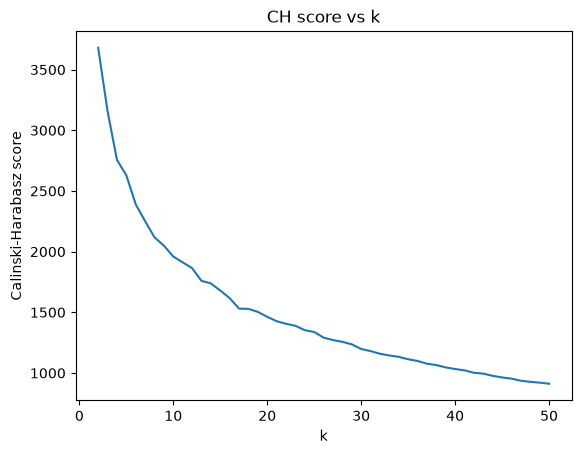

In [14]:
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score
import matplotlib.pyplot as plt

def choose_k_ch(X_data, k_values, seed):
    best_k = None
    best_score = -1
    scores = {}
    for k in k_values:
        km = KMeans(n_clusters=k, n_init=10, random_state=seed)
        cluster_labels = km.fit_predict(X_data)
        score = calinski_harabasz_score(X_data, cluster_labels)
        scores[k] = score
        if score > best_score:
            best_score = score
            best_k = k
    return best_k, scores


k_values = range(2, 51)
best_k, ch_scores = choose_k_ch(X, k_values, seed=0)
print("best k:", best_k)

plt.plot(list(ch_scores.keys()), list(ch_scores.values()))
plt.xlabel("k")
plt.ylabel("Calinski-Harabasz score")
plt.title("CH score vs k")
plt.show()


### (b) Determine which family is the majority

In [17]:
def majority_labels_per_cluster(cluster_labels, Y_true):
    majority = {}
    for cluster in np.unique(cluster_labels):
        rows_in_cluster = Y_true[cluster_labels == cluster]
        majority[cluster] = {
            "Family": rows_in_cluster["Family"].mode()[0],
            "Genus": rows_in_cluster["Genus"].mode()[0],
            "Species": rows_in_cluster["Species"].mode()[0],
        }
    return majority


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [19]:
km = KMeans(n_clusters=best_k, n_init=10, random_state=0)
cluster_labels = km.fit_predict(X)
majority = majority_labels_per_cluster(cluster_labels, Y)

def assign_majority_labels(cluster_labels, majority):
    rows = [majority[cluster] for cluster in cluster_labels]
    return pd.DataFrame(rows, columns=["Family", "Genus", "Species"])

pred_labels = assign_majority_labels(cluster_labels, majority)

print("hamming distance:", hamming_distance(Y, pred_labels))
print("hamming score:", hamming_score(Y, pred_labels))
print("hamming loss:", hamming_loss(Y, pred_labels))

hamming_distances = []

for run in range(50):
    best_ch = -1
    best_cluster_labels = None
    for k in range(2, 51):
        km = KMeans(n_clusters=k, n_init=10, random_state=run)
        cluster_labels_k = km.fit_predict(X)
        ch = calinski_harabasz_score(X, cluster_labels_k)
        if ch > best_ch:
            best_ch = ch
            best_cluster_labels = cluster_labels_k

    majority_run = majority_labels_per_cluster(best_cluster_labels, Y)
    pred_labels_run = assign_majority_labels(best_cluster_labels, majority_run)
    hamming_distances.append(hamming_distance(Y, pred_labels_run))

print("average Hamming distance:", np.mean(hamming_distances))
print("std of Hamming distance:", np.std(hamming_distances))

hamming distance: 0.8956219596942321
hamming score: 0.7014593467685893
hamming loss: 0.29854065323141066
average Hamming distance: 0.895621959694232
std of Hamming distance: 1.1102230246251565e-16


## 3. ISLR 12.6.2

a.

for complete linkage, we start by grouping 1 and 2, who are the closest pair at .3. Then we compare (1,2) with 3 and with 4, and compare 3 and 4. The next smallest group is (3,4), since (1,2) with either 3 or 4 must be the furthest pairs distance, which is .5. Fially, we group (1,2) and (3,4), and the height of this merge, as the furthest distance, is .8. (plot below)

b. 

for single linkage, (1,2) is still the first pair, then it becomes (1,2) and 3 with a merge height of .4, because we take the shortest of the two values between 1 and 3 and 2 and 3. Then we just have (1,2,3) and 4, and the smallest distance here is .45.  (plot below)


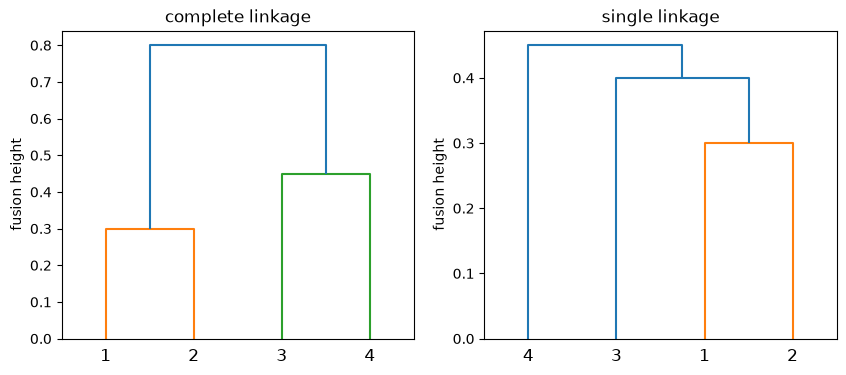

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

D = np.array([
    [0, 0.3, 0.4, 0.7],
    [0.3, 0, 0.5, 0.8],
    [0.4, 0.5, 0, 0.45],
    [0.7, 0.8, 0.45, 0],
])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, method in zip(axes, ["complete", "single"]):
    Z = linkage(squareform(D), method=method)
    dendrogram(Z, labels=[1, 2, 3, 4], ax=ax)
    ax.set_title(f"{method} linkage")
    ax.set_ylabel("fusion height")
plt.show()

c. 

Two get two clusters, we cut at a height between 0.45 and 0.8 where there are two branches. One contains observations 1 and 2, and the other contains observations 3 and 4, wso the two clusters are {1, 2} and {3, 4}.

d. 

We'd have to cut between .4 and .45 to cut across two branches and get two clusters. On the left, we have observation 4, and on the right we have the group of (1,2,3), which would be the other cluster. 

e. 

The left-right position of the two branches at any fusion can be swapped without changing the meaning of a dendrogram, since the meaning depends only on which observations fuse and at what height. I can reposition the leaves into the order 4, 3, 2, 1, which doesn't change where the observations fuse and at what height, just the order in which they appear. (plot below)

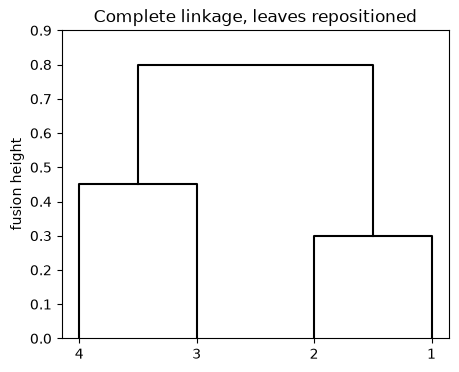

In [23]:
import matplotlib.pyplot as plt

order = [4, 3, 2, 1]

x = {}
for i, obs in enumerate(order):
    x[obs] = i

def fuse(ax, x_left, h_left, x_right, h_right, height):
    ax.plot([x_left, x_left, x_right, x_right], [h_left, height, height, h_right], color="black")
    return (x_left + x_right) / 2

fig, ax = plt.subplots(figsize=(5, 4))

mid_43 = fuse(ax, x[4], 0, x[3], 0, 0.45)
mid_21 = fuse(ax, x[2], 0, x[1], 0, 0.3)
fuse(ax, mid_43, 0.45, mid_21, 0.3, 0.8)

ax.set_xticks(range(4))
ax.set_xticklabels(order)
ax.set_ylabel("fusion height")
ax.set_title("Complete linkage, leaves repositioned")
ax.set_ylim(0, 0.9)
plt.show()